# Results analysis (Student 4)
Training curves, results table, error breakdown and error analysis for the report.
**Rule:** test-split numbers come only from the final, dev-selected checkpoint.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

# finds the repo root and makes src/ importable
repo = Path.cwd()
if not (repo / "configs").is_dir():
    repo = repo.parent
sys.path.insert(0, str(repo / "src"))

from conformer_asr.evaluation.metrics import edit_counts, normalize
from conformer_asr.evaluation.visualization import (load_scalars, plot_error_breakdown,
                                                    plot_loss_curves, plot_scalar)

# settings: need to change for real run
RUN = "fake_run" # Noah's experiment_name
TAG = "best" # checkpoint tag used by evaluate.py
SELECTED_STEP = 4500 # step of the selected checkpoint

log_dir = repo / "outputs" / "tensorboard" / RUN
metrics_dir = repo / "outputs" / "metrics"
predictions_dir = repo / "outputs" / "predictions"
fig_dir = repo / "docs" / "report" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
print("repo:", repo)
print("log dir exists:", log_dir.is_dir())

repo: c:\Users\Evan Graff\Speech-Recognition-Using-Conformer
log dir exists: True


## 1. Training curves

Logged scalars: ['train/learning_rate', 'train/loss', 'val/cer', 'val/loss', 'val/wer']


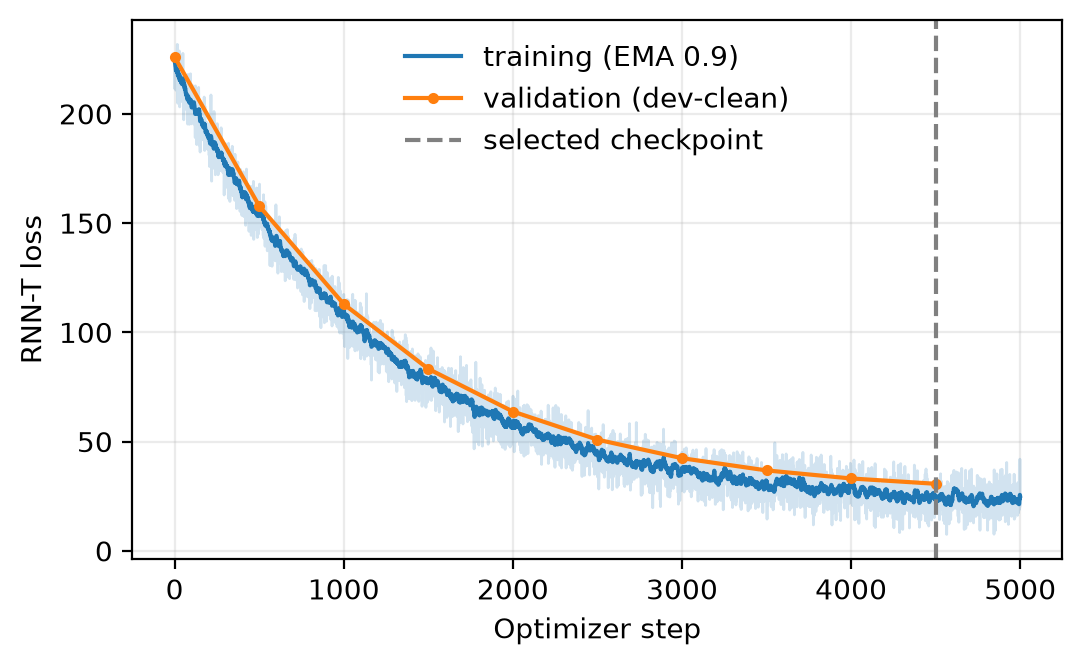

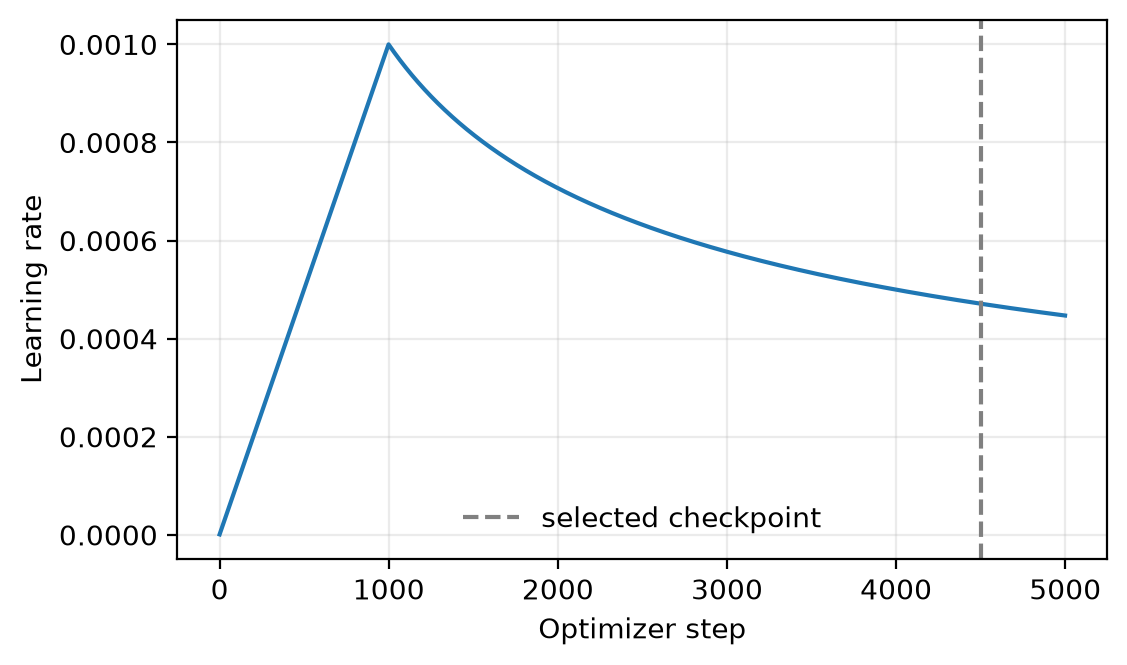

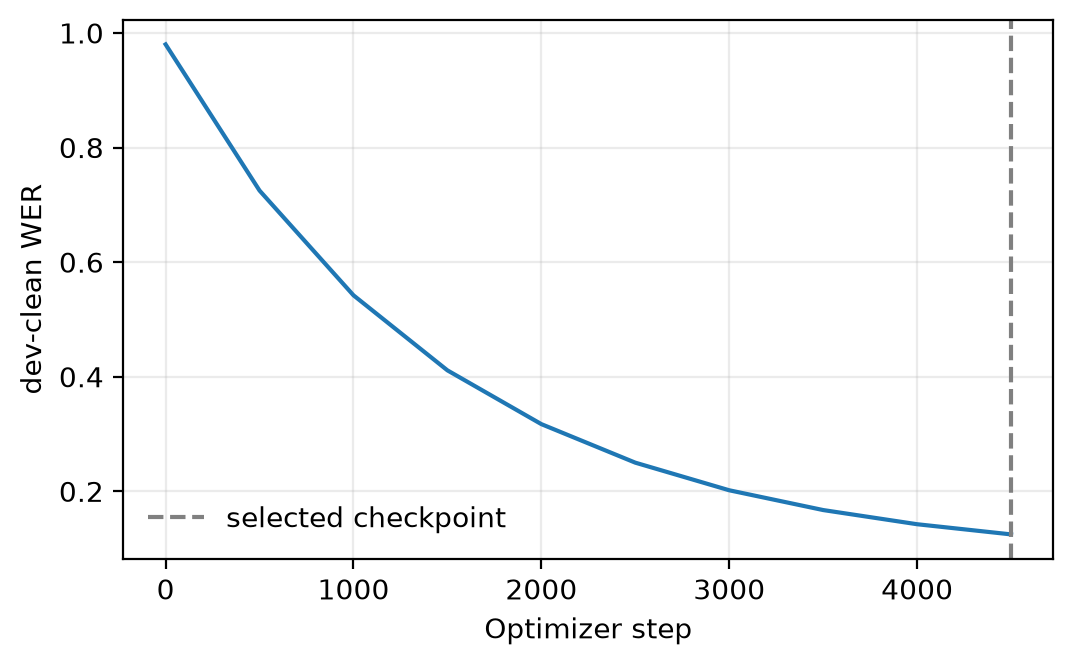

In [3]:
series = load_scalars(log_dir)
print("Logged scalars:", sorted(series))

plot_loss_curves(log_dir, fig_dir / "loss_curves", smoothing=0.9, selected_step=SELECTED_STEP)
plot_scalar(log_dir, "train/learning_rate", fig_dir / "learning_rate", "Learning rate",
            selected_step=SELECTED_STEP)
plot_scalar(log_dir, "val/wer", fig_dir / "val_wer", "dev-clean WER", selected_step=SELECTED_STEP)

for name in ("loss_curves", "learning_rate", "val_wer"):
    display(Image(filename=str(fig_dir / f"{name}.png"), width=500))